In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
    confusion_matrix
)

%matplotlib inline

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [2]:
PROJECT_DIR = Path.cwd().parent

OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)

Output directory: d:\spamEmail\unsaturated\outputs


In [6]:
X_reduced = np.load(OUTPUT_DIR / "X_reduced.npy")

y_true = np.load(OUTPUT_DIR / "y_true.npy")

source = np.load(
    OUTPUT_DIR / "source.npy",
    allow_pickle=True
)

print("Feature matrix shape:", X_reduced.shape)
print("Label shape:", y_true.shape)
print("Source shape:", source.shape)

print("\nAvailable sources:")
print(np.unique(source))

Feature matrix shape: (108671, 100)
Label shape: (108671,)
Source shape: (108671,)

Available sources:
['trec5' 'trec6' 'trec7']


In [7]:
print("Contains NaN:", np.isnan(X_reduced).any())
print("Contains infinity:", np.isinf(X_reduced).any())

print("\nNumber of emails:", X_reduced.shape[0])
print("Number of dimensions:", X_reduced.shape[1])

Contains NaN: False
Contains infinity: False

Number of emails: 108671
Number of dimensions: 100


In [8]:
kmeans = KMeans(
    n_clusters=2,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_reduced)

print("K-Means clustering completed!")

K-Means clustering completed!


In [9]:
cluster_counts = pd.Series(
    kmeans_labels
).value_counts().sort_index()

print("Cluster distribution:")
print(cluster_counts)

print("\nCluster percentages:")
print(
    (cluster_counts / len(kmeans_labels) * 100).round(2)
)

Cluster distribution:
0    51497
1    57174
Name: count, dtype: int64

Cluster percentages:
0    47.39
1    52.61
Name: count, dtype: float64


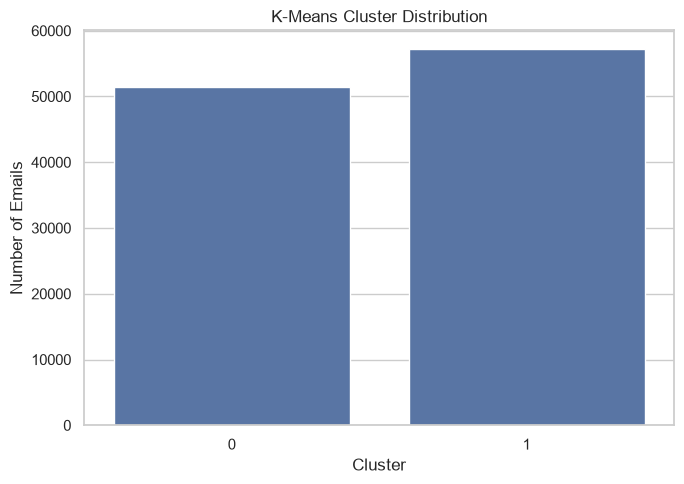

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=kmeans_labels
)

plt.title("K-Means Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Emails")

plt.tight_layout()
plt.show()

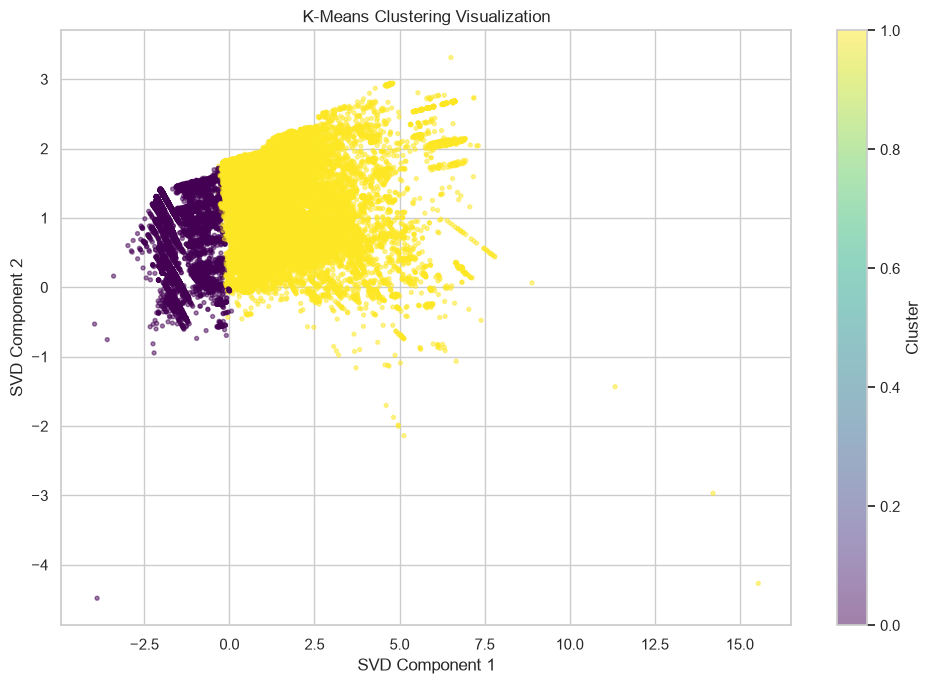

In [11]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=8,
    alpha=0.5
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("K-Means Clustering Visualization")

plt.colorbar(scatter, label="Cluster")

plt.tight_layout()
plt.show()

In [12]:
print("K-Means Inertia:", kmeans.inertia_)

K-Means Inertia: 666360.4498824929


In [13]:
silhouette = silhouette_score(
    X_reduced,
    kmeans_labels,
    sample_size=10000,
    random_state=RANDOM_STATE
)

print("Silhouette Score:", round(silhouette, 4))

Silhouette Score: 0.3321


In [14]:
ari = adjusted_rand_score(
    y_true,
    kmeans_labels
)

nmi = normalized_mutual_info_score(
    y_true,
    kmeans_labels
)

print("Adjusted Rand Index:", round(ari, 4))
print("Normalized Mutual Information:", round(nmi, 4))

Adjusted Rand Index: 0.0754
Normalized Mutual Information: 0.0591


In [15]:
comparison = pd.crosstab(
    pd.Series(y_true, name="Actual Label"),
    pd.Series(kmeans_labels, name="Cluster")
)

comparison

Cluster,0,1
Actual Label,,
0.0,36359,24278
1.0,15138,32896


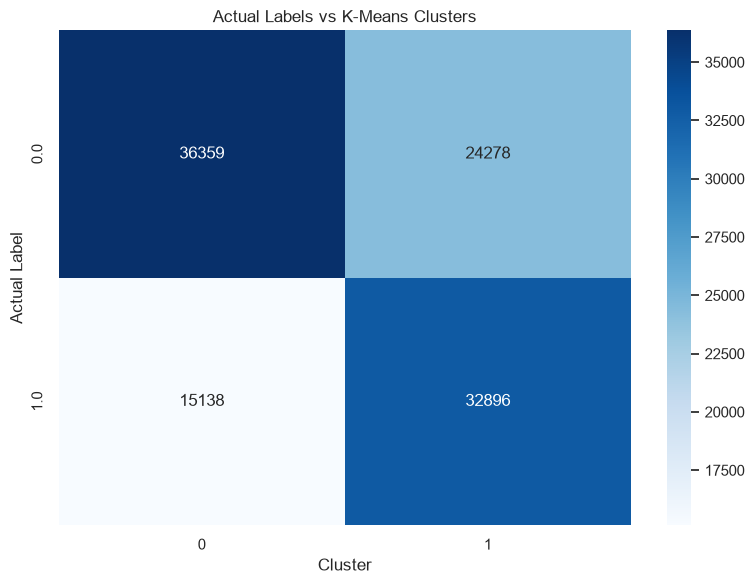

In [16]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    comparison,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Actual Labels vs K-Means Clusters")
plt.tight_layout()
plt.show()

In [17]:
source_cluster_table = pd.crosstab(
    pd.Series(source, name="Source"),
    pd.Series(kmeans_labels, name="Cluster")
)

source_cluster_table

Cluster,0,1
Source,,
trec5,29169,20403
trec6,9177,5826
trec7,13151,30945


In [18]:
source_cluster_percentage = (
    source_cluster_table.div(
        source_cluster_table.sum(axis=0),
        axis=1
    ) * 100
)

source_cluster_percentage.round(2)

Cluster,0,1
Source,,
trec5,56.64,35.69
trec6,17.82,10.19
trec7,25.54,54.12


In [19]:
source_results = []

for source_name in np.unique(source):

    mask = source == source_name

    source_labels = y_true[mask]
    source_clusters = kmeans_labels[mask]

    ari_source = adjusted_rand_score(
        source_labels,
        source_clusters
    )

    nmi_source = normalized_mutual_info_score(
        source_labels,
        source_clusters
    )

    source_results.append({
        "Source": source_name,
        "Number of Emails": mask.sum(),
        "ARI": ari_source,
        "NMI": nmi_source
    })

source_results_df = pd.DataFrame(source_results)

source_results_df

,Source,Number of Emails,ARI,NMI
0,trec5,49572,0.438371,0.333754
1,trec6,15003,0.111553,0.063645
2,trec7,44096,0.032989,0.053161


In [20]:
np.save(
    OUTPUT_DIR / "kmeans_labels.npy",
    kmeans_labels
)

joblib_path = OUTPUT_DIR / "kmeans_model.joblib"

import joblib

joblib.dump(
    kmeans,
    joblib_path
)

comparison.to_csv(
    OUTPUT_DIR / "kmeans_label_comparison.csv"
)

source_results_df.to_csv(
    OUTPUT_DIR / "kmeans_source_evaluation.csv",
    index=False
)

print("K-Means results saved successfully!")

K-Means results saved successfully!


In [21]:
print("K-MEANS CLUSTERING SUMMARY")
print("--------------------------")

print("Total emails:", len(kmeans_labels))
print("Number of clusters:", kmeans.n_clusters)

print("\nCluster sizes:")
print(cluster_counts)

print("\nInertia:", round(kmeans.inertia_, 2))
print("Silhouette Score:", round(silhouette, 4))
print("ARI:", round(ari, 4))
print("NMI:", round(nmi, 4))

print("\nSource-wise evaluation:")
print(source_results_df)

print("\nK-Means clustering completed!")

K-MEANS CLUSTERING SUMMARY
--------------------------
Total emails: 108671
Number of clusters: 2

Cluster sizes:
0    51497
1    57174
Name: count, dtype: int64

Inertia: 666360.45
Silhouette Score: 0.3321
ARI: 0.0754
NMI: 0.0591

Source-wise evaluation:
  Source  Number of Emails       ARI       NMI
0  trec5             49572  0.438371  0.333754
1  trec6             15003  0.111553  0.063645
2  trec7             44096  0.032989  0.053161

K-Means clustering completed!
